In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df = pd.read_csv("dataset/emails.csv", encoding="ISO-8859-1")
# Drop unnecessary columns if present
if "Email No." in df.columns:
    df = df.drop(columns=["Email No."])
# Ensure label is integer
df["Prediction"] = df["Prediction"].astype(int)
# Features & target
X = df.drop(columns=["Prediction"])
y = df["Prediction"]
# Print basic info
print(df.columns)
print(df.head(5))

Index(['the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='str', length=3001)
   the  to  ect  and  for  of    a  you  hou  in  ...  connevey  jay  valued  \
0    0   0    1    0    0   0    2    0    0   0  ...         0    0       0   
1    8  13   24    6    6   2  102    1   27  18  ...         0    0       0   
2    0   0    1    0    0   0    8    0    0   4  ...         0    0       0   
3    0   5   22    0    5   1   51    2   10   1  ...         0    0       0   
4    7   6   17    1    5   2   57    0    9   3  ...         0    0       0   

   lay  infrastructure  military  allowing  ff  dry  Prediction  
0    0               0         0         0   0    0           0  
1    0               0         0         0   1    0           0  
2    0               0         0         0   0    0           0  
3    0              

In [14]:
X_train,X_test, y_train,y_test= train_test_split(
X,y, test_size=0.2,random_state=42,stratify=y
)

In [15]:
knn= KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train,y_train)
y_pred_knn= knn.predict(X_test)
print("\n---KNNPerformance---")
print("Accuracy:",accuracy_score(y_test,y_pred_knn))
print("Classification Report:\n",classification_report(y_test,y_pred_knn))
print("ConfusionMatrix:\n",confusion_matrix(y_test,y_pred_knn))


---KNNPerformance---
Accuracy: 0.8714975845410629
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.88      0.91       735
           1       0.74      0.85      0.79       300

    accuracy                           0.87      1035
   macro avg       0.84      0.86      0.85      1035
weighted avg       0.88      0.87      0.87      1035

ConfusionMatrix:
 [[648  87]
 [ 46 254]]


In [16]:
svm= SVC(kernel='linear',random_state=42) #Linearkernelforbinaryclassification
svm.fit(X_train,y_train)
y_pred_svm= svm.predict(X_test)
print("\n---SVMPerformance---")
print("Accuracy:",accuracy_score(y_test,y_pred_svm))
print("Classification Report:\n",classification_report(y_test,y_pred_svm))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))


---SVMPerformance---
Accuracy: 0.9671497584541063
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.97      0.98       735
           1       0.94      0.95      0.94       300

    accuracy                           0.97      1035
   macro avg       0.96      0.96      0.96      1035
weighted avg       0.97      0.97      0.97      1035

Confusion Matrix:
 [[716  19]
 [ 15 285]]


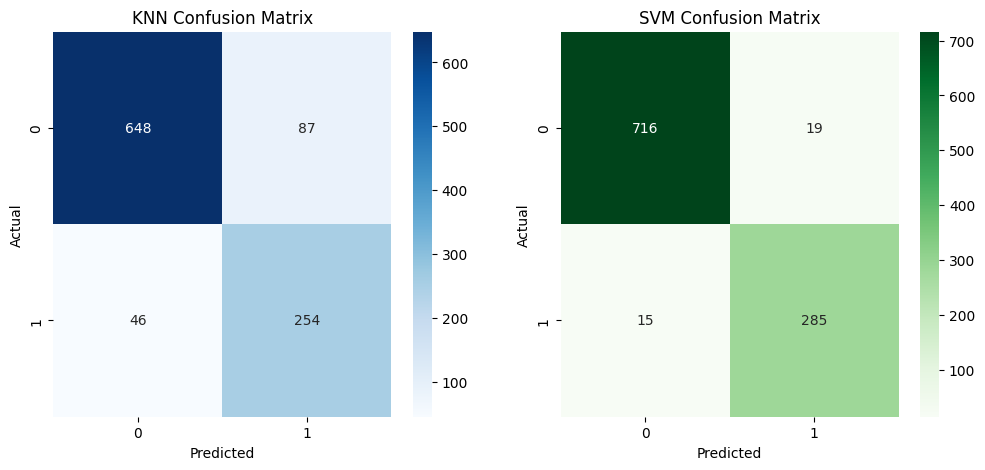

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt="d",cmap="Blues", ax=ax[0])
ax[0].set_title("KNN Confusion Matrix")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt="d",cmap="Greens", ax=ax[1])
ax[1].set_title("SVM Confusion Matrix")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Actual")
plt.show()